# Crear un meme con OpenCV
Kodland M5L1. Ejemplo reproducible que crea un dibujo geométrico original, sustituye su fondo negro y añade un pie de foto. No requiere que copies código ni aportes una imagen para probarlo. También puedes cambiar la ruta para usar tu propia foto. Ejecutado localmente con Python, no en el servidor de Colab.

In [1]:
import importlib.util, subprocess, sys
for module, package in [('cv2','opencv-python-headless'),('numpy','numpy')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,'-m','pip','install',package])
import cv2
import numpy as np
from pathlib import Path

In [2]:
def crear_ejemplo():
    image = np.zeros((500, 800, 3), dtype=np.uint8)
    cv2.rectangle(image, (230, 130), (570, 400), (220, 170, 70), -1)
    cv2.rectangle(image, (270, 70), (530, 230), (230, 210, 150), -1)
    cv2.circle(image, (340, 145), 23, (70, 40, 20), -1)
    cv2.circle(image, (460, 145), 23, (70, 40, 20), -1)
    cv2.line(image, (340, 190), (460, 190), (70, 40, 20), 8)
    cv2.imwrite('imagen_original.png', image)
    return image

def change_back(background, image):
    if background is None or image is None:
        raise ValueError('No se pudo leer una imagen')
    background = cv2.resize(background, (image.shape[1], image.shape[0]))
    mask = np.all(image <= 10, axis=2)
    return np.where(mask[..., None], background, image).astype(np.uint8)

def agregar_pie(image, text, y=455):
    if image is None:
        raise ValueError('La imagen no se pudo cargar')
    result = image.copy()
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 1.1
    while cv2.getTextSize(text, font, font_scale, 2)[0][0] > image.shape[1] - 40:
        font_scale *= .9
    width = cv2.getTextSize(text, font, font_scale, 2)[0][0]
    origin = ((image.shape[1] - width) // 2, min(y, image.shape[0] - 20))
    cv2.putText(result, text, origin, font, font_scale, (0,0,0), 7, cv2.LINE_AA)
    cv2.putText(result, text, origin, font, font_scale, (255,255,255), 2, cv2.LINE_AA)
    return result


Ejemplo ejecutado localmente; imagen guardada en meme_con_texto.png
Fondo sustituido, pie de foto aplicado y archivo verificado.


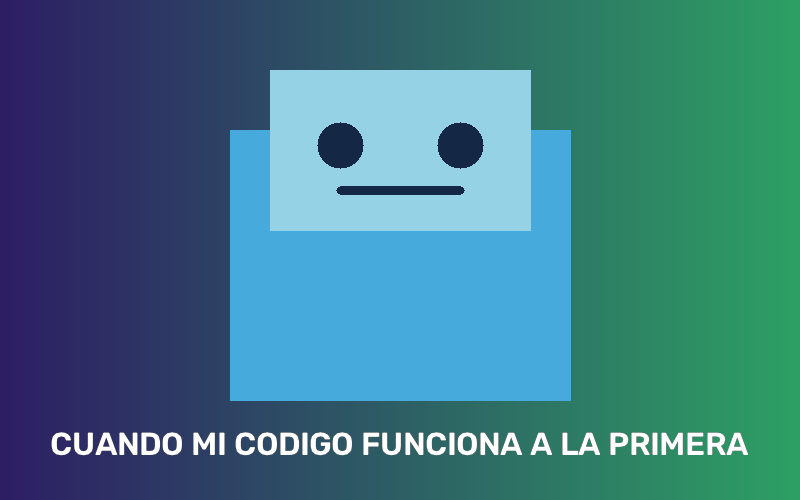

In [3]:
crear_ejemplo()
image = cv2.imread('imagen_original.png')
background = np.zeros_like(image)
background[:] = (100, 65, 45)
background[:, :, 1] = np.linspace(30, 160, image.shape[1], dtype=np.uint8)[None, :]
image = change_back(background, image)
cv2.imwrite('fondo_cambiado.png', image)
image = cv2.imread('fondo_cambiado.png')
image_with_text = agregar_pie(image, 'CUANDO MI CODIGO FUNCIONA A LA PRIMERA')
assert cv2.imwrite('meme_con_texto.png', image_with_text)
assert image_with_text.shape == (500,800,3)
assert np.any(image_with_text != image)
try:
    from google.colab.patches import cv2_imshow
    cv2_imshow(image_with_text)
except ImportError:
    print('Ejemplo ejecutado localmente; imagen guardada en meme_con_texto.png')
print('Fondo sustituido, pie de foto aplicado y archivo verificado.')


## Notas
El color de OpenCV usa el orden BGR. El filtro de fondo negro es apropiado para este dibujo; para una foto con fondo complejo se necesitaría una máscara de segmentación. La fuente Hershey funciona mejor con textos sin acentos. El archivo PNG queda guardado junto al cuaderno.